# Ejecutar el restaurador de fotos en Google Colab

1. Activá la GPU: *Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU*.
2. Ejecutá las celdas en orden.
3. Abrí el link público que aparece al final.

In [1]:
# Verificar que hay GPU
!nvidia-smi

Tue Nov 17 00:16:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Clonar el repositorio (cambiar RAMA si hace falta)
RAMA = "feature/modelado"
!git clone -b {RAMA} https://github.com/alvarito1709/imagenes-TI-marketplace-gen.git
%cd imagenes-TI-marketplace-gen

Cloning into 'imagenes-TI-marketplace-gen'...
remote: Enumerating objects: 52, done.
remote: Counting objects: 100% (52/52), done.
remote: Compressing objects: 100% (33/33), done.
remote: Total 52 (delta 9), reused 50 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (52/52), 57.22 KiB | 4.09 MiB/s, done.
Resolving deltas: 100% (9/9), done.
/content/imagenes-TI-marketplace-gen


In [3]:
# Instalar dependencias (Colab ya trae torch con CUDA, no lo reinstalamos)
!pip install -q gradio diffusers transformers accelerate opencv-python-headless pillow numpy

Entrada: (512, 512), intensidad=0.3
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
config.json: 100% 955/955 [00:00<00:00, 4.32MB/s]
An error occurred while trying to fetch lllyasviel/control_v11f1e_sd15_tile: lllyasviel/control_v11f1e_sd15_tile does not appear to have a file named diffusion_pytorch_model.safetensors.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.

diffusion_pytorch_model.bin: downloading bytes:  16% 226M/1.45G [00:01<00:05, 243MB/s, 18.4MB/s  ]  
diffusion_pytorch_model.bin: downloading bytes:  20% 284M/1.45G [00:01<00:04, 255MB/s, 23.7MB/s  ]
diffusion_pytorch_model.bin: downloading bytes:  22% 313M/1.45G [00:02<00:05, 215MB/s, 27.4MB/s  ]  ]
diffusion_pytorch_model.bin: downloading bytes:  48% 692M/1.45G [00:03<00

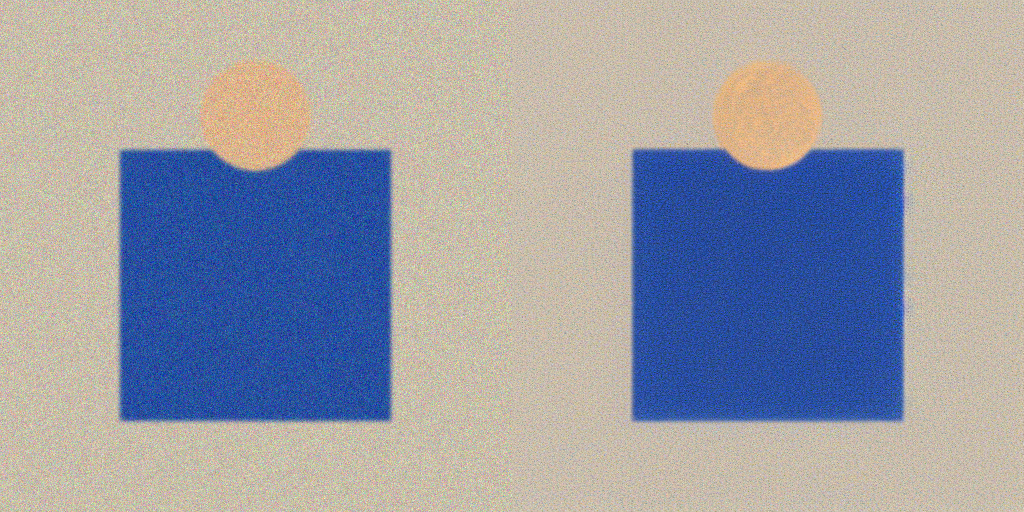

In [4]:
# Prueba rápida del modelo, sin interfaz (la primera vez descarga ~5 GB)
!python scripts/prueba_difusion.py
from IPython.display import Image as Img, display
display(Img('salidas/prueba_difusion.png'))

In [5]:
# Lanzar la app; share=True genera un link público temporal
from app import demo
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://276358c22d666edb4e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
An error occurred while trying to fetch lllyasviel/control_v11f1e_sd15_tile: lllyasviel/control_v11f1e_sd15_tile does not appear to have a file named diffusion_pytorch_model.safetensors.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is 

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

Traceback (most recent call last):
  File "/content/imagenes-TI-marketplace-gen/app.py", line 22, in procesar
    objetos_antes = analysis.detectar_objetos(original)
  File "/content/imagenes-TI-marketplace-gen/src/analysis.py", line 21, in detectar_objetos
    raise NotImplementedError("Pendiente")
NotImplementedError: Pendiente

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/gradio/queueing.py", line 870, in process_events
    response = await route_utils.call_process_api(
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<6 lines>...
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/gradio/route_utils.py", line 418, in call_process_api
    output = await app.get_blocks().process_api(
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<12 lines>...
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 2698, in process_api
    r